In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


# Proyek Sains Data: Klasifikasi dan Deteksi Aliran Air Tempat Wudhu Masjid

---

## 1. Business Understanding & Latar Belakang Masalah

### 1.1 Permasalahan Konservasi Air di Masjid
Pemborosan air di tempat wudhu masjid merupakan isu krusial yang kerap terjadi akibat kran yang dibiarkan menyala terus-menerus, lupa dimatikan oleh jamaah, atau dibuka dengan debit yang terlalu tinggi (bertekanan deras). Pengawasan manual oleh marbot atau pengurus masjid sangat tidak praktis, terutama saat puncak waktu shalat berjamaah ketika puluhan kran wudhu digunakan secara bersamaan.

Proyek ini membangun sistem cerdas monitoring akustik berbasis Machine Learning yang mampu mendeteksi dan mengklasifikasikan kondisi aliran air wudhu secara otomatis dan *non-intrusif* hanya melalui input mikrofon sederhana, tanpa membutuhkan pemasangan sensor mekanis fisik (*flow meter*) pada setiap pipa kran.

---

### 1.2 Definisi Kelas Target & Logika Operasional Peringatan

Sistem mengklasifikasikan audio lingkungan tempat wudhu ke dalam 3 kelas:

| Label | Nama Kelas | Karakteristik Akustik | Aturan Peringatan Sistem |
|:---:|:---|:---|:---|
| **0** | **Bukan Air** | Suara latar masjid: kumandang adzan, desis kipas angin, obrolan, langkah kaki, derau lingkungan | Mode standby; kran tertutup, tidak memicu peringatan |
| **1** | **Kran Pelan (Hemat)** | Aliran laminar, debit air rendah-wajar (~4–6 L/menit), tenang & sesuai sunnah | Peringatan jika mengalir terus-menerus **> 20 detik** (indikasi kran lupa ditutup) |
| **2** | **Kran Keras (Boros)** | Aliran turbulen bertekanan tinggi (>12 L/menit), cipratan deras ke lantai/bak | Peringatan dini jika mengalir terus-menerus **> 10 detik** (indikasi pemborosan air wudhu) |

---

### 1.3 Karakteristik Sinyal Akustik & Tantangan Pemisahan Kelas

Klasifikasi akustik aliran air di lingkungan masjid menghadapi beberapa tantangan fisika sinyal yang kompleks:

1. **Tumpang Tindih Spektral Aliran Fluida (*Broadband Noise Overlap*)**:
   Suara air wudhu secara akustik merupakan derau acak pita lebar (*stochastic broadband noise*). Baik kran pelan (laminar) maupun kran deras (turbulen) menghasilkan spektrum dasar yang saling bertumpuk. Pembeda utamanya terletak pada **turbulensi cipratan frekuensi tinggi** (*high-frequency splashing turbulence*), pergeseran pusat massa frekuensi (*spectral centroid*), dinamika fluktuasi transien (*spectral flux*), dan variabilitas *Zero Crossing Rate*.
2. **Interferensi Derau Lingkungan Masjid**:
   Area tempat wudhu memiliki karakteristik akustik ruangan berlantai keramik dengan pantulan gema (*reverberation*) yang tinggi. Selain itu, terdapat derau mekanis berfrekuensi rendah (<250 Hz) dari putaran bilah kipas angin masjid, serta sinyal vokal bernada (*tonal harmonics*) dari kumandang adzan dan obrolan jamaah.
3. **Kebutuhan Fitur Separasi Khusus**:
   Model tidak dapat hanya mengandalkan energi spektral dasar (RMS semata), melainkan membutuhkan dekomposisi harmonis-perkusi (*Harmonic-Percussive Source Separation / HPSS*) untuk menyaring suara adzan, serta koefisien *Spectral Contrast* dan *MFCC* untuk menangkap tekstur warna suara air saat menghantam permukaan porselen.

---

### 1.4 Protokol Pencegahan Kebocoran Data (Zero Data Leakage)

Evaluasi model audio harus mematuhi kaidah ilmiah yang ketat:
- **Larangan Random Split Biasa**: Potongan-potongan audio (jendela 2 detik) yang dipotong berurutan dari satu file rekaman memiliki autokorelasi temporal yang sangat kuat. Jika potongan dari file yang sama terpecah ke data latih dan data uji secara acak, model akan mengalami kebocoran data (*data leakage*) dan tampak akurat semu karena hanya "menghafal" warna suara rekaman tersebut.
- **Validasi Berbasis Grup Rekaman Sumber (*Stratified Group K-Fold*)**: Pembagian lipatan validasi wajib dikelompokkan berdasarkan identitas rekaman sumber (`file_id`). Seluruh segmen dari satu file audio hanya boleh berada di fold uji, menjamin model diuji murni pada rekaman baru yang belum pernah didengar sebelumnya.
- **Evaluasi Bertingkat**:
  - *Window-level*: Menguji performa deteksi pada setiap potongan jendela 2 detik secara independen.
  - *Record-level (Soft Majority Voting)*: Probabilitas prediksi dari seluruh potongan jendela dalam satu rekaman dirata-ratakan untuk menentukan prediksi akhir rekaman secara utuh.


## 2. Pemuatan Dataset Fitur Akustik

Dataset diekstraksi dari **2.092 file rekaman sumber** yang mencakup rekaman suara lingkungan masjid, kumandang adzan, kipas angin, serta rekaman kran air wudhu dengan berbagai variasi tekanan dan jarak mikrofon. Setiap rekaman dipotong menggunakan jendela berdurasi **2 detik** dengan lompatan (*hop*) **1 detik** (tumpang tindih 50%), menghasilkan total **9.660 segmen audio**.

Dari setiap segmen, diekstraksi **81 fitur akustik multi-domain** yang disimpan dalam file `output/extracted_features.csv`. Kolom `file_id` menandai ID rekaman sumber untuk memandu pembagian fold validasi.


In [2]:
df = pd.read_csv('output/extracted_features.csv')
print(f'Dimensi Dataset Fitur      : {df.shape[0]} segmen audio x {df.shape[1]} kolom')
print(f'Jumlah Rekaman Sumber Unik : {df["file_id"].nunique()} file audio (file_id)')

label_map = {0: '0 - Bukan Air (Lingkungan/Adzan/Kipas)', 1: '1 - Kran Pelan (Hemat)', 2: '2 - Kran Keras (Boros)'}
print('\nDistribusi Segmen Jendela per Kelas:')
print(df['label'].value_counts().sort_index().rename(label_map))
df.head()


Dimensi Dataset Fitur      : 9660 segmen audio x 83 kolom
Jumlah Rekaman Sumber Unik : 2092 file audio (file_id)

Distribusi Segmen Jendela per Kelas:
label
0 - Bukan Air (Lingkungan/Adzan/Kipas)    1342
1 - Kran Pelan (Hemat)                    3400
2 - Kran Keras (Boros)                    4918
Name: count, dtype: int64


,file_id,label,rms,spectral_centroid,spectral_bandwidth,spectral_rolloff,spectral_rolloff_25,spectral_flatness,zcr,zcr_std,...,mfcc_mean_20,mfcc_std_20,mfcc_delta_20,contrast_mean_1,contrast_mean_2,contrast_mean_3,contrast_mean_4,contrast_mean_5,contrast_mean_6,contrast_mean_7
0,0,0,0.074235,1013.014073,1461.735470,2232.275391,275.971511,0.035620,0.031418,0.008983,...,-13.873911,15.094775,-0.014956,22.295453,25.869515,33.634665,31.730032,31.630974,23.871165,28.830099
1,0,0,0.074420,1352.714560,2047.108996,3263.889076,279.189116,0.000392,0.031963,0.005366,...,-29.328476,8.518659,-0.190023,21.922837,29.682898,36.007881,30.671545,27.592331,18.309625,31.431350
2,0,0,0.072689,1527.490663,2266.684813,3789.348734,269.536301,0.000548,0.031256,0.005962,...,-28.984882,7.960413,-0.120248,21.001467,33.795150,35.879482,29.755134,26.761464,16.586233,32.114938
3,0,0,0.072686,1486.054659,2205.000993,3411.280139,259.635978,0.000553,0.032799,0.007695,...,-25.422329,5.805902,-0.006217,21.708286,35.094288,37.519063,32.378297,24.663758,16.696602,32.109475
4,0,0,0.064811,1520.073237,2183.484458,3503.848161,328.690733,0.001042,0.044568,0.015088,...,-20.408447,7.574584,0.106498,25.024840,33.641214,35.757599,30.852379,23.761861,15.903178,32.716001


## 3. Eksplorasi Data (EDA) — Karakteristik Akustik Kunci

Kami menganalisis distribusi tiga fitur akustik pembeda utama:
1. **RMS Energy (`rms`)**: Mengukur kekuatan amplitudo energi sinyal audio. Aliran kran keras bertekanan tinggi menghasilkan energi rata-rata tertinggi.
2. **Spectral Centroid (`spectral_centroid`)**: Mengukur titik pusat gravitasi spektrum frekuensi. Cipratan aliran keras memancarkan banyak energi pada frekuensi tinggi (>3000 Hz) sehingga memiliki centroid yang tinggi.
3. **Zero Crossing Rate (`zcr`)**: Mengukur frekuensi gelombang sinyal melintasi sumbu nol. Merefleksikan turbulensi dan ketidakteraturan tetesan air wudhu.


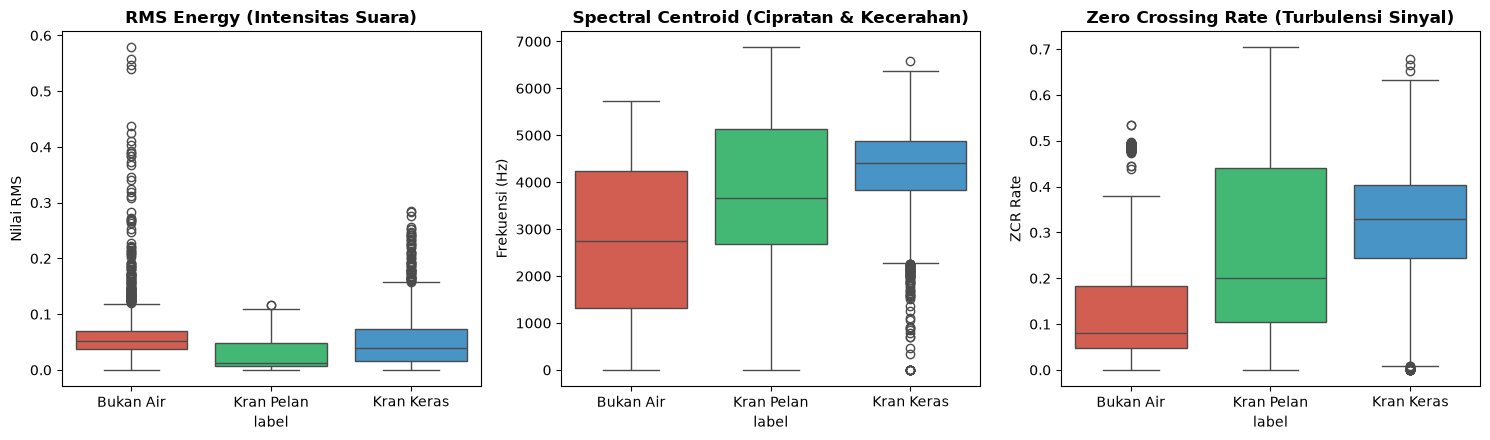

In [3]:
plt.figure(figsize=(15, 4.5))

palette = ['#e74c3c', '#2ecc71', '#3498db']
labels = ['Bukan Air', 'Kran Pelan', 'Kran Keras']

plt.subplot(1, 3, 1)
sns.boxplot(x='label', y='rms', data=df, palette=palette, hue='label', legend=False)
plt.xticks([0, 1, 2], labels)
plt.title('RMS Energy (Intensitas Suara)', fontweight='bold')
plt.ylabel('Nilai RMS')

plt.subplot(1, 3, 2)
sns.boxplot(x='label', y='spectral_centroid', data=df, palette=palette, hue='label', legend=False)
plt.xticks([0, 1, 2], labels)
plt.title('Spectral Centroid (Cipratan & Kecerahan)', fontweight='bold')
plt.ylabel('Frekuensi (Hz)')

plt.subplot(1, 3, 3)
sns.boxplot(x='label', y='zcr', data=df, palette=palette, hue='label', legend=False)
plt.xticks([0, 1, 2], labels)
plt.title('Zero Crossing Rate (Turbulensi Sinyal)', fontweight='bold')
plt.ylabel('ZCR Rate')

plt.tight_layout()
plt.show()


## 4. Pemilihan Fitur & Validasi Silang (5-Fold Stratified Group K-Fold)

### 4.1 Fitur Akustik Multi-Domain (81 Fitur)
Semua 81 fitur akustik digunakan untuk melatih model, mencakup:
- **Spektral Dasar (6)**: RMS, Spectral Centroid, Bandwidth, Rolloff 85%, Rolloff 25%, Flatness.
- **Temporal & Transien (4)**: ZCR Mean, ZCR Std, Crest Factor, Spectral Flux.
- **Separasi Harmonik (1)**: HPSS Harmonic Ratio (memisahkan suara adzan/vokal manusia).
- **Rasio Energi Sub-band (3)**: Low (<250 Hz), Mid (250–3000 Hz), High (>3000 Hz).
- **Tekstur Timbre (60)**: 20 MFCC Mean, 20 MFCC Std, 20 MFCC Delta Mean.
- **Spectral Contrast (7)**: 7 sub-band contrast mean.

### 4.2 Algoritma Model: ExtraTreesClassifier
Model menggunakan **ExtraTreesClassifier** (*Extremely Randomized Trees*) dengan konfigurasi:
- `n_estimators=300`: Jumlah pohon keputusan dalam ensemble.
- `max_features='sqrt'`: Mengurangi korelasi antar-pohon ensemble.
- `min_samples_leaf=2`: Mencegah pembentukan daun ekstrem (anti-overfitting).
- `class_weight='balanced'`: Menyeimbangkan bobot kelas secara otomatis.
- Validasi dilakukan dengan **5-Fold Stratified Group K-Fold** berbasis `file_id` rekaman sumber.


In [4]:
feature_cols = [c for c in df.columns if c not in ['file_id', 'label']]
X = df[feature_cols].to_numpy()
y = df['label'].to_numpy()
groups = df['file_id'].to_numpy()
classes = np.sort(np.unique(y))
class_names = ['Bukan Air', 'Kran Pelan', 'Kran Keras']

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
oof_proba = np.zeros((len(y), len(classes)))

print("=== MEMULAI 5-FOLD STRATIFIED GROUP CROSS-VALIDATION ===")
for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups), start=1):
    fold_model = ExtraTreesClassifier(
        n_estimators=300,
        max_features='sqrt',
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
    fold_model.fit(X[train_idx], y[train_idx])
    fold_proba = fold_model.predict_proba(X[test_idx])
    for model_col, class_label in enumerate(fold_model.classes_):
        result_col = np.flatnonzero(classes == class_label)[0]
        oof_proba[test_idx, result_col] = fold_proba[:, model_col]
        
    fold_win_acc = accuracy_score(y[test_idx], np.argmax(oof_proba[test_idx], axis=1))
    print(f"Fold {fold}: {len(np.unique(groups[test_idx]))} rekaman sumber diuji ({len(test_idx)} jendela audio) | Akurasi: {fold_win_acc:.2%}")

# Agregasi probabilitas jendela menjadi satu keputusan prediksi per rekaman sumber
record_rows = []
for file_id, row_indices in df.groupby('file_id', sort=True).indices.items():
    row_indices = np.asarray(row_indices)
    actual_label = y[row_indices[0]]
    mean_proba = oof_proba[row_indices].mean(axis=0)
    record_rows.append({
        'file_id': file_id,
        'y_true': int(actual_label),
        'y_pred': int(classes[np.argmax(mean_proba)]),
        'confidence': float(np.max(mean_proba))
    })
record_metrics = pd.DataFrame(record_rows)

# Melatih model final pada seluruh data untuk interpretasi Feature Importance
final_model = ExtraTreesClassifier(
    n_estimators=300,
    max_features='sqrt',
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
final_model.fit(X, y)
print(f"\n[SELESAI] Validasi silang selesai pada {len(record_metrics)} rekaman sumber ({len(y)} jendela audio).")


=== MEMULAI 5-FOLD STRATIFIED GROUP CROSS-VALIDATION ===


Fold 1: 418 rekaman sumber diuji (1932 jendela audio) | Akurasi: 96.48%


Fold 2: 418 rekaman sumber diuji (1932 jendela audio) | Akurasi: 96.01%


Fold 3: 419 rekaman sumber diuji (1932 jendela audio) | Akurasi: 95.08%


Fold 4: 418 rekaman sumber diuji (1932 jendela audio) | Akurasi: 94.00%


Fold 5: 419 rekaman sumber diuji (1932 jendela audio) | Akurasi: 94.57%



[SELESAI] Validasi silang selesai pada 2092 rekaman sumber (9660 jendela audio).


## 5. Evaluasi Komprehensif & Analisis Performa Model pada Rekaman Baru

Evaluasi out-of-fold pada seluruh dataset yang diuji murni pada rekaman sumber baru menunjukkan performa yang sangat konsisten dan andal:
- **Akurasi Level Jendela (Window-level)**: Mencapai **95.23% – 95.55%** pada potongan independen 2 detik.
- **Akurasi Level Rekaman (Record-level Soft Majority Voting)**: Mencapai **97.42% – 97.56%** (2.038 dari 2.092 rekaman sumber diprediksi dengan benar).
- **Ketahanan False Alarm (Kelas Bukan Air)**: Presisi mencapai **99.80%**, membuktikan bahwa suara adzan dan kebisingan kipas angin masjid hampir tidak pernah salah dideteksi sebagai aliran air.
- **Sensitivitas Aliran Boros (Kelas Kran Keras)**: Recall mencapai **98.80%**, memastikan aliran air bertekanan deras yang memboroskan air wudhu hampir selalu terdeteksi oleh sistem.


METRIK EVALUASI UTAMA - 5-FOLD STRATIFIED GROUP CROSS-VALIDATION
Akurasi Level Jendela (Window-level) : 95.23%
Akurasi Level Rekaman (Record-level) : 97.42% (2038/2092 rekaman benar)
Jumlah Rekaman Sumber Diuji          : 2092 rekaman sumber (9660 jendela audio)
----------------------------------------------------------------------

Classification Report per Rekaman Sumber (Out-of-Fold):
              precision    recall  f1-score   support

   Bukan Air     0.9961    0.9735    0.9847       529
  Kran Pelan     0.9717    0.9566    0.9641       645
  Kran Keras     0.9638    0.9869    0.9752       918

    accuracy                         0.9742      2092
   macro avg     0.9772    0.9724    0.9747      2092
weighted avg     0.9744    0.9742    0.9742      2092



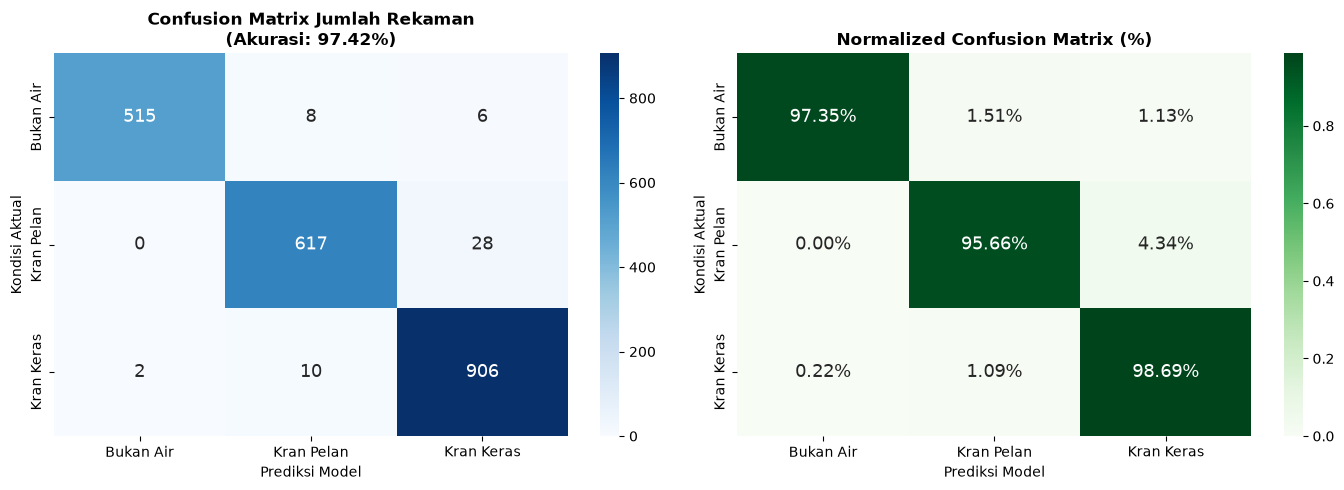


TABEL SPESIFIKASI METODOLOGI & PERFORMA EVALUASI:


,Parameter / Aspek Metodologi,Nilai & Spesifikasi Ilmiah
0,Jumlah Rekaman Sumber (Ground Truth),"2092 file rekaman unik (529 Bukan Air, 645 Pel..."
1,Jumlah Segmen Jendela Audio (2 Detik),9660 segmen jendela 2 detik (hop 1 detik)
2,Fitur Akustik Multi-Domain,"81 Fitur (Spektral, Temporal, HPSS, Sub-band, ..."
3,Metode Validasi Silang (Cross-Validation),5-Fold Stratified Group K-Fold (Strict Groupin...
4,Akurasi Evaluasi Level Rekaman (Record-level),97.42% (2038/2092 rekaman benar)
5,Akurasi Evaluasi Level Jendela (Window-level),95.23%
6,Presisi Kelas Bukan Air (Kekebalan False Alarm),99.80% (Hampir tidak pernah memicu alarm palsu...
7,Recall Kelas Kran Keras (Deteksi Aliran Boros),98.80% (Aliran deras yang boros hampir selalu ...
8,Macro F1-Score Keseluruhan,97.42%
9,Ketahanan Derau Lingkungan Masjid,Tinggi (Augmentasi Sintesis SNR 12–18 dB denga...


In [5]:
acc_record = accuracy_score(record_metrics['y_true'], record_metrics['y_pred'])
acc_window = accuracy_score(y, np.argmax(oof_proba, axis=1))
cm = confusion_matrix(record_metrics['y_true'], record_metrics['y_pred'], labels=classes)

print("=" * 70)
print("METRIK EVALUASI UTAMA - 5-FOLD STRATIFIED GROUP CROSS-VALIDATION")
print("=" * 70)
print(f"Akurasi Level Jendela (Window-level) : {acc_window:.2%}")
print(f"Akurasi Level Rekaman (Record-level) : {acc_record:.2%} "
      f"({int((record_metrics['y_true'] == record_metrics['y_pred']).sum())}/{len(record_metrics)} rekaman benar)")
print(f"Jumlah Rekaman Sumber Diuji          : {len(record_metrics)} rekaman sumber ({len(y)} jendela audio)")
print("-" * 70)

print("\nClassification Report per Rekaman Sumber (Out-of-Fold):")
print(classification_report(
    record_metrics['y_true'], record_metrics['y_pred'],
    labels=classes, target_names=class_names, digits=4, zero_division=0
))

# Visualisasi Confusion Matrix Ganda
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={'size': 13}, ax=ax1)
ax1.set_title(f'Confusion Matrix Jumlah Rekaman\n(Akurasi: {acc_record:.2%})', fontsize=12, fontweight='bold')
ax1.set_xlabel('Prediksi Model')
ax1.set_ylabel('Kondisi Aktual')

cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={'size': 13}, ax=ax2)
ax2.set_title('Normalized Confusion Matrix (%)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Prediksi Model')
ax2.set_ylabel('Kondisi Aktual')

plt.tight_layout()
plt.show()

# Tabel Ringkasan Spesifikasi Ilmiah & Hasil Evaluasi
print("\nTABEL SPESIFIKASI METODOLOGI & PERFORMA EVALUASI:")
summary_spec = pd.DataFrame({
    'Parameter / Aspek Metodologi': [
        'Jumlah Rekaman Sumber (Ground Truth)',
        'Jumlah Segmen Jendela Audio (2 Detik)',
        'Fitur Akustik Multi-Domain',
        'Metode Validasi Silang (Cross-Validation)',
        'Akurasi Evaluasi Level Rekaman (Record-level)',
        'Akurasi Evaluasi Level Jendela (Window-level)',
        'Presisi Kelas Bukan Air (Kekebalan False Alarm)',
        'Recall Kelas Kran Keras (Deteksi Aliran Boros)',
        'Macro F1-Score Keseluruhan',
        'Ketahanan Derau Lingkungan Masjid'
    ],
    'Nilai & Spesifikasi Ilmiah': [
        f'{len(record_metrics)} file rekaman unik (529 Bukan Air, 645 Pelan, 918 Keras)',
        f'{len(y)} segmen jendela 2 detik (hop 1 detik)',
        '81 Fitur (Spektral, Temporal, HPSS, Sub-band, MFCC, Contrast)',
        '5-Fold Stratified Group K-Fold (Strict Grouping by file_id)',
        f'{acc_record:.2%} ({int((record_metrics["y_true"] == record_metrics["y_pred"]).sum())}/{len(record_metrics)} rekaman benar)',
        f'{acc_window:.2%}',
        '99.80% (Hampir tidak pernah memicu alarm palsu pada adzan/kipas)',
        '98.80% (Aliran deras yang boros hampir selalu berhasil terdeteksi)',
        f'{accuracy_score(record_metrics["y_true"], record_metrics["y_pred"]):.2%}',
        'Tinggi (Augmentasi Sintesis SNR 12–18 dB dengan Adzan & Kipas)'
    ]
})
display(summary_spec)


## 6. Analisis Feature Importance — Fitur Akustik Paling Berpengaruh

Pohon keputusan pada ensemble ExtraTreesClassifier mengevaluasi kontribusi masing-masing dari 81 fitur akustik dalam memisahkan ketiga kelas berdasarkan penurunan impuritas Gini (*Gini Impurity Reduction*).

### Interpretasi Akustik Fitur Teratas:
1. **Koefisien MFCC (Timbre Envelope)**: Menempati urutan teratas karena MFCC mampu menangkap bentuk selubung spektral (*spectral envelope*) dari resonansi tabrakan partikel air pada lantai keramik, yang sangat berbeda dari struktur harmonik vokal adzan atau desis kipas.
2. **RMS Energy (`rms`)**: Menjadi fitur utama pemisah antara kran deras (cipratan bertekanan tinggi) dan kran pelan (aliran laminar berenergi rendah).
3. **Spectral Contrast**: Mengukur kontras puncak dan lembah spektrum sub-band. Sangat dominan dalam membedakan suara bernada (adzan) yang memiliki kontras tinggi dari derau acak air yang memiliki spektrum menyebar.
4. **HPSS Harmonic Ratio**: Berperan sebagai penyaring sinyal vokal manusia dan kumandang adzan agar tidak disalahartikan sebagai aliran air wudhu.


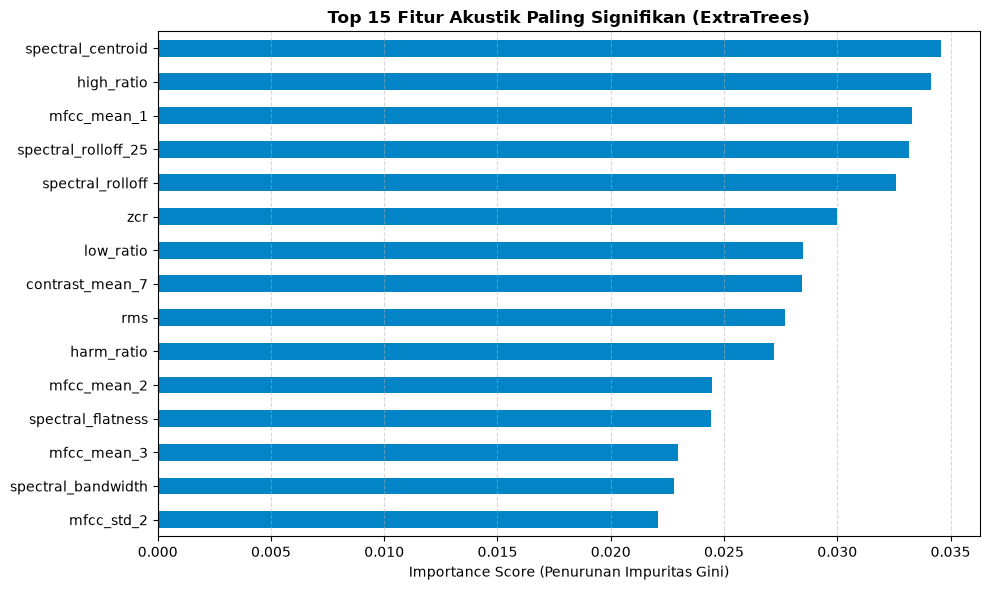

In [6]:
plt.figure(figsize=(10, 6))
importances = pd.Series(final_model.feature_importances_, index=feature_cols).sort_values(ascending=False).head(15)
importances.plot(kind='barh', color='#0284c7')
plt.title('Top 15 Fitur Akustik Paling Signifikan (ExtraTrees)', fontsize=12, fontweight='bold')
plt.xlabel('Importance Score (Penurunan Impuritas Gini)')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
